# Quantum-Aware Risk Assessment for Long-Term Medical Data Storage
## Research extension to the AES Grover demo

This notebook adds a real-world case study to the existing project. It does **not** implement a full AES reversible quantum oracle and does **not** break AES-128 or AES-256.

**Case study:** synthetic medical records that must remain confidential over long retention periods. We validate ordinary AES encryption/decryption, experimentally simulate Grover search only in a tiny toy keyspace, and separately calculate idealized theoretical query counts for real AES key sizes.

Run this notebook from the repository root so `grover_utils.py` can be imported.


In [1]:
pip install qiskit qiskit-aer pycryptodome matplotlib numpy pandas

export PATH="/opt/homebrew/opt/llvm/bin:$PATH"
export PATH="$HOME/Library/Python/3.9/bin:$PATH"



[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: /Users/gargisupe/Quantum-Cryptoanalysis-of-AES/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import json
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes

from grover_utils import (
    build_grover_circuit,
    run_counts,
    success_probability,
    make_noise_model,
    optimal_grover_iterations,
)


## 1. Create a synthetic medical-record dataset

The records below are fictional and contain no real patient data. We use them only to make the application context concrete. AES-GCM provides authenticated encryption, so decryption also verifies that the ciphertext has not been modified.


In [3]:
synthetic_records = [
    {"record_id": "SYN-001", "age": 34, "visit_type": "routine_checkup", "diagnosis_code": "Z00.00"},
    {"record_id": "SYN-002", "age": 58, "visit_type": "cardiology_followup", "diagnosis_code": "I10"},
    {"record_id": "SYN-003", "age": 22, "visit_type": "orthopedic_consult", "diagnosis_code": "M25.50"},
    {"record_id": "SYN-004", "age": 71, "visit_type": "diabetes_followup", "diagnosis_code": "E11.9"},
    {"record_id": "SYN-005", "age": 46, "visit_type": "imaging_review", "diagnosis_code": "R51.9"},
]

records_json = json.dumps(synthetic_records, indent=2).encode("utf-8")
print(f"Synthetic records: {len(synthetic_records)}")
print(f"Serialized payload size: {len(records_json)} bytes")
print(records_json.decode("utf-8"))


Synthetic records: 5
Serialized payload size: 605 bytes
[
  {
    "record_id": "SYN-001",
    "age": 34,
    "visit_type": "routine_checkup",
    "diagnosis_code": "Z00.00"
  },
  {
    "record_id": "SYN-002",
    "age": 58,
    "visit_type": "cardiology_followup",
    "diagnosis_code": "I10"
  },
  {
    "record_id": "SYN-003",
    "age": 22,
    "visit_type": "orthopedic_consult",
    "diagnosis_code": "M25.50"
  },
  {
    "record_id": "SYN-004",
    "age": 71,
    "visit_type": "diabetes_followup",
    "diagnosis_code": "E11.9"
  },
  {
    "record_id": "SYN-005",
    "age": 46,
    "visit_type": "imaging_review",
    "diagnosis_code": "R51.9"
  }
]


## 2. Encrypt and decrypt records using real AES

This is a conventional classical cryptography demonstration, not a quantum attack. We use AES-GCM with randomly generated 128-bit and 256-bit keys. Keep keys separate from ciphertext in a real system; key management is often as important as the cipher choice.


In [4]:
def aes_gcm_round_trip(payload: bytes, key_bits: int) -> dict:
    if key_bits not in (128, 256):
        raise ValueError("key_bits must be 128 or 256")

    key = get_random_bytes(key_bits // 8)
    cipher = AES.new(key, AES.MODE_GCM)
    ciphertext, tag = cipher.encrypt_and_digest(payload)

    decryptor = AES.new(key, AES.MODE_GCM, nonce=cipher.nonce)
    recovered = decryptor.decrypt_and_verify(ciphertext, tag)

    return {
        "AES key size": f"AES-{key_bits}",
        "key bits": key_bits,
        "nonce bytes": len(cipher.nonce),
        "ciphertext bytes": len(ciphertext),
        "authentication tag bytes": len(tag),
        "round-trip verified": recovered == payload,
        "ciphertext differs from plaintext": ciphertext != payload,
    }

encryption_df = pd.DataFrame([
    aes_gcm_round_trip(records_json, 128),
    aes_gcm_round_trip(records_json, 256),
])
encryption_df


,AES key size,key bits,nonce bytes,ciphertext bytes,authentication tag bytes,round-trip verified,ciphertext differs from plaintext
0,AES-128,128,16,605,16,True,True
1,AES-256,256,16,605,16,True,True


## 3. Theoretical search-cost comparison

For an unstructured search with one marked key, idealized Grover query complexity is approximately \(\frac{\pi}{4}\sqrt{N}\), where \(N=2^k\). This is a query-count model only: each query in a real AES attack must implement a reversible AES computation and key check, which is very costly.

The retention period (for example, 5, 15, or 30 years) does **not** mathematically change AES's keyspace or Grover's query count. It is included as a data-governance scenario to discuss how long confidentiality must be maintained—not as a variable in the cryptographic complexity formula.


In [5]:
def grover_query_estimate(key_bits: int) -> float:
    # Idealized one-marked-item estimate; not a wall-clock runtime.
    return (math.pi / 4.0) * (2 ** (key_bits / 2))

key_sizes = [128, 192, 256]
quantum_cost_df = pd.DataFrame([
    {
        "Cipher": f"AES-{bits}",
        "Key bits": bits,
        "Classical exhaustive-search scale": f"2^{bits}",
        "Idealized Grover query scale": f"~2^{bits // 2}",
        "Approx. Grover query estimate": grover_query_estimate(bits),
        "Important caveat": "Query count only; excludes reversible AES circuit cost",
    }
    for bits in key_sizes
])
quantum_cost_df


,Cipher,Key bits,Classical exhaustive-search scale,Idealized Grover query scale,Approx. Grover query estimate,Important caveat
0,AES-128,128,2^128,~2^64,1.448804e+19,Query count only; excludes reversible AES circ...
1,AES-192,192,2^192,~2^96,6.222565e+28,Query count only; excludes reversible AES circ...
2,AES-256,256,2^256,~2^128,2.672571e+38,Query count only; excludes reversible AES circ...


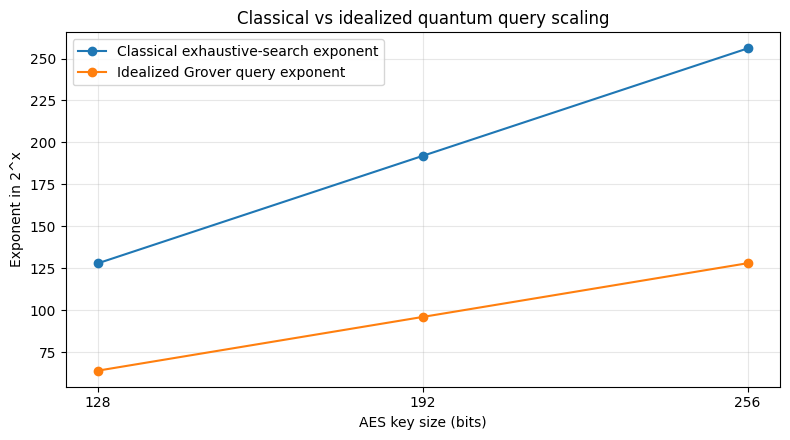

In [6]:
# Plot exponent scales rather than enormous absolute numbers.
bits = np.array(key_sizes)
plt.figure(figsize=(8, 4.5))
plt.plot(bits, bits, marker="o", label="Classical exhaustive-search exponent")
plt.plot(bits, bits / 2, marker="o", label="Idealized Grover query exponent")
plt.xlabel("AES key size (bits)")
plt.ylabel("Exponent in 2^x")
plt.title("Classical vs idealized quantum query scaling")
plt.xticks(bits)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 4. Run a controlled toy-keyspace Grover experiment

This section uses the repository's existing simplified phase oracle. It marks a target basis state directly; it does **not** reversibly compute AES(key, plaintext) and compare the ciphertext. Therefore the circuit demonstrates Grover amplitude amplification, not AES key recovery.

Start small (3–5 qubits) to keep simulation quick.


In [7]:
N_QUBITS = 4
TARGET_KEY = 9
SHOTS = 2048
ITERATION_VALUES = range(0, 6)

if not (0 <= TARGET_KEY < 2 ** N_QUBITS):
    raise ValueError("TARGET_KEY must fit in N_QUBITS")

toy_rows = []
for iterations in ITERATION_VALUES:
    circuit = build_grover_circuit(
        n_qubits=N_QUBITS,
        target=TARGET_KEY,
        iterations=iterations,
        measure=True,
    )
    counts = run_counts(circuit, shots=SHOTS, seed=1234)
    toy_rows.append({
        "qubits": N_QUBITS,
        "keyspace_size": 2 ** N_QUBITS,
        "target_key": TARGET_KEY,
        "iterations": iterations,
        "shots": SHOTS,
        "success_probability": success_probability(counts, TARGET_KEY, N_QUBITS),
    })

toy_results_df = pd.DataFrame(toy_rows)
toy_results_df


,qubits,keyspace_size,target_key,iterations,shots,success_probability
0,4,16,9,0,2048,0.062500
1,4,16,9,1,2048,0.481445
2,4,16,9,2,2048,0.898438
3,4,16,9,3,2048,0.958984
4,4,16,9,4,2048,0.579590
5,4,16,9,5,2048,0.122559


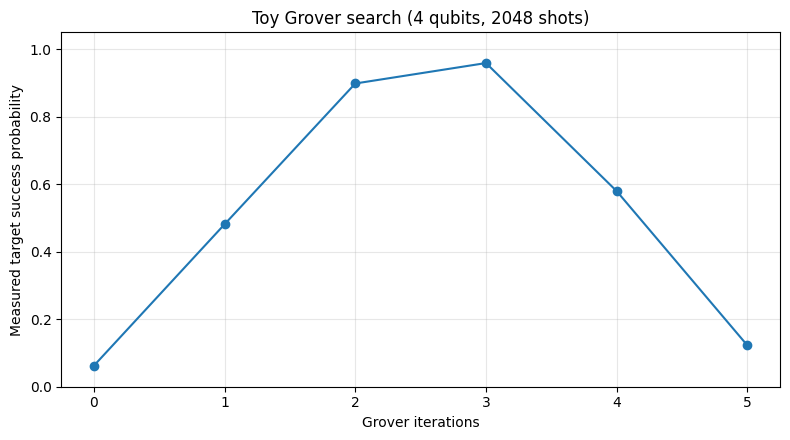

The theoretical optimal iteration count is approximately: 3


In [8]:
plt.figure(figsize=(8, 4.5))
plt.plot(
    toy_results_df["iterations"],
    toy_results_df["success_probability"],
    marker="o",
)
plt.xlabel("Grover iterations")
plt.ylabel("Measured target success probability")
plt.ylim(0, 1.05)
plt.title(f"Toy Grover search ({N_QUBITS} qubits, {SHOTS} shots)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("The theoretical optimal iteration count is approximately:",
      optimal_grover_iterations(N_QUBITS))


## 5. Noise-aware toy experiment

We compare ideal simulation with depolarizing noise at two illustrative probabilities. These are simulator settings, not calibrated estimates for a particular quantum processor. Noise results depend on the circuit, transpilation, simulator model, and shot count.


In [9]:
NOISE_PROBABILITIES = [0.0, 0.01, 0.03]
ITERATIONS_FOR_NOISE = optimal_grover_iterations(N_QUBITS)
noise_rows = []

circuit = build_grover_circuit(
    n_qubits=N_QUBITS,
    target=TARGET_KEY,
    iterations=ITERATIONS_FOR_NOISE,
    measure=True,
)

for p in NOISE_PROBABILITIES:
    noise_model = None if p == 0 else make_noise_model("depolarizing", p)
    counts = run_counts(circuit, shots=SHOTS, noise_model=noise_model, seed=2026)
    noise_rows.append({
        "noise model": "ideal" if p == 0 else "depolarizing",
        "error probability setting": p,
        "grover iterations": ITERATIONS_FOR_NOISE,
        "success probability": success_probability(counts, TARGET_KEY, N_QUBITS),
    })

noise_results_df = pd.DataFrame(noise_rows)
noise_results_df


,noise model,error probability setting,grover iterations,success probability
0,ideal,0.00,3,0.959473
1,depolarizing,0.01,3,0.637695
2,depolarizing,0.03,3,0.325684


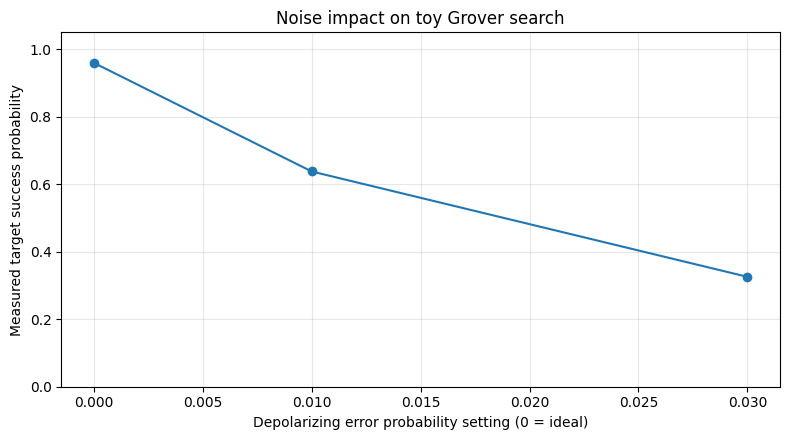

In [10]:
plt.figure(figsize=(8, 4.5))
plt.plot(
    noise_results_df["error probability setting"],
    noise_results_df["success probability"],
    marker="o",
)
plt.xlabel("Depolarizing error probability setting (0 = ideal)")
plt.ylabel("Measured target success probability")
plt.ylim(0, 1.05)
plt.title("Noise impact on toy Grover search")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Data-retention scenarios and interpretation

The following table connects the cryptographic estimates to the application scenario. It intentionally does not convert years of retention into a break-time prediction: that would require assumptions about future hardware, fault tolerance, oracle implementation cost, and attacker resources.


In [11]:
retention_years = [5, 15, 30]
retention_df = pd.DataFrame([
    {
        "retention period (years)": years,
        "data context": "synthetic medical records",
        "AES-128 idealized Grover query scale": "~2^64",
        "AES-256 idealized Grover query scale": "~2^128",
        "interpretation": (
            "Retention duration increases the period for which confidentiality must hold; "
            "it does not change the keyspace or query-complexity formula."
        ),
    }
    for years in retention_years
])
retention_df


,retention period (years),data context,AES-128 idealized Grover query scale,AES-256 idealized Grover query scale,interpretation
0,5,synthetic medical records,~2^64,~2^128,Retention duration increases the period for wh...
1,15,synthetic medical records,~2^64,~2^128,Retention duration increases the period for wh...
2,30,synthetic medical records,~2^64,~2^128,Retention duration increases the period for wh...


## 7. Conclusions and limitations

- AES-GCM encryption/decryption works for the synthetic example with both AES-128 and AES-256.
- The toy Grover circuit demonstrates amplitude amplification over a small search space.
- Noise can reduce measured success probability; the exact trend should be reported from the executed runs, not assumed in advance.
- Idealized Grover query scaling is quadratic in the size of an unstructured search, often summarized as reducing the exponent from \(k\) to roughly \(k/2\).
- These experiments do **not** implement a reversible AES oracle and do **not** demonstrate recovery of real AES-128/256 keys.
- Practical risk assessments must consider reversible circuit gate count/depth, fault-tolerant overhead, hardware capabilities, and key-management practices.
- For long-lived sensitive data, use well-maintained cryptographic libraries, sound key management, and a documented cryptographic-agility plan. AES-256 is not a universal fix for poor implementation or compromised keys.

### Suggested results to record for the report
1. Encryption/decryption validation table.
2. Toy Grover success probability versus iteration count.
3. Toy Grover success probability versus noise setting.
4. Classical versus idealized Grover query-scaling plot.
5. A short paragraph explaining why retention period is a governance factor, not an input to Grover's complexity formula.
